Charger les données dans une dataframe 

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [37]:
data= pd.read_csv("apps (1).csv")
data.head()

,App,Category,Rating,Reviews,Size_MBs,Installs,Type,Price,Content_Rating,Genres,Last_Updated,Android_Ver
0,Ak Parti Yardım Toplama,SOCIAL,NaN,0,8.7,0,Paid,$13.99,Teen,Social,"July 28, 2017",4.1 and up
1,Ain Arabic Kids Alif Ba ta,FAMILY,NaN,0,33.0,0,Paid,$2.99,Everyone,Education,"April 15, 2016",3.0 and up
2,Popsicle Launcher for Android P 9.0 launcher,PERSONALIZATION,NaN,0,5.5,0,Paid,$1.49,Everyone,Personalization,"July 11, 2018",4.2 and up
3,Command & Conquer: Rivals,FAMILY,NaN,0,19.0,0,NaN,0,Everyone 10+,Strategy,"June 28, 2018",Varies with device
4,CX Network,BUSINESS,NaN,0,10.0,0,Free,0,Everyone,Business,"August 6, 2018",4.1 and up


2. Combien de lignes et de colonnes contient df_apps ? Quels sont les noms 
des colonnes ? Regardez un échantillon aléatoire de 5 lignes différentes.

In [38]:
print("le nombre de ligne et de colonne est :",data.shape)
print("------------------------------------------------------")
print("Nom des colonnes:\n", data.columns)
print("------------------------------------------------------")
print("Echantillon aliatoire de 5 ligne est:")
data.sample(5)

le nombre de ligne et de colonne est : (10841, 12)
------------------------------------------------------
Nom des colonnes:
 Index(['App', 'Category', 'Rating', 'Reviews', 'Size_MBs', 'Installs', 'Type',
       'Price', 'Content_Rating', 'Genres', 'Last_Updated', 'Android_Ver'],
      dtype='object')
------------------------------------------------------
Echantillon aliatoire de 5 ligne est:


,App,Category,Rating,Reviews,Size_MBs,Installs,Type,Price,Content_Rating,Genres,Last_Updated,Android_Ver
7232,Nick Jr. - Shows & Games,ENTERTAINMENT,4.2,8968,35.0,"1,000,000",Free,0,Everyone,Entertainment;Music & Video,"January 23, 2018",4.4 and up
10356,Firefox Browser fast & private,COMMUNICATION,4.4,3075118,3.5,"100,000,000",Free,0,Everyone,Communication,"July 10, 2018",Varies with device
2288,QUI EST CE ?,FAMILY,NaN,7,5.4,"1,000",Free,0,Everyone,Puzzle,"October 11, 2015",2.2 and up
7495,Dr. Chess,GAME,4.1,97209,6.7,"1,000,000",Free,0,Everyone,Board,"January 14, 2018",4.0.3 and up
335,BT Position Sender - Bluetooth Position Sender,TOOLS,NaN,0,2.9,10,Free,0,Everyone,Tools,"July 3, 2018",4.4 and up


3. Supprimez les colonnes appelées Last_Updated et Android_Version du 
DataFrame. Nous n'utiliserons pas ces colonnes.

In [39]:
data.drop(columns=["Last_Updated", "Android_Ver"], inplace = True)

In [40]:
data.head(5)

,App,Category,Rating,Reviews,Size_MBs,Installs,Type,Price,Content_Rating,Genres
0,Ak Parti Yardım Toplama,SOCIAL,NaN,0,8.7,0,Paid,$13.99,Teen,Social
1,Ain Arabic Kids Alif Ba ta,FAMILY,NaN,0,33.0,0,Paid,$2.99,Everyone,Education
2,Popsicle Launcher for Android P 9.0 launcher,PERSONALIZATION,NaN,0,5.5,0,Paid,$1.49,Everyone,Personalization
3,Command & Conquer: Rivals,FAMILY,NaN,0,19.0,0,NaN,0,Everyone 10+,Strategy
4,CX Network,BUSINESS,NaN,0,10.0,0,Free,0,Everyone,Business


4. Combien de lignes ont une valeur NaN (not-a-number) dans la colonne 
Ratings ? imputez les valeurs manquantes et créez un DataFrame appelé 
df_apps_clean.

In [41]:
data[data.isnull().any(axis=1)].head()


,App,Category,Rating,Reviews,Size_MBs,Installs,Type,Price,Content_Rating,Genres
0,Ak Parti Yardım Toplama,SOCIAL,NaN,0,8.7,0,Paid,$13.99,Teen,Social
1,Ain Arabic Kids Alif Ba ta,FAMILY,NaN,0,33.0,0,Paid,$2.99,Everyone,Education
2,Popsicle Launcher for Android P 9.0 launcher,PERSONALIZATION,NaN,0,5.5,0,Paid,$1.49,Everyone,Personalization
3,Command & Conquer: Rivals,FAMILY,NaN,0,19.0,0,NaN,0,Everyone 10+,Strategy
4,CX Network,BUSINESS,NaN,0,10.0,0,Free,0,Everyone,Business


In [42]:
data.loc[(data["Reviews"] == 0) & (data["Rating"].isnull()), "Rating"] = 0
print("Correct -_/")

Correct -_/


In [43]:
select_rows_apres = data[(data["Reviews"] == 0) & (data["Rating"].isnull())].shape[0]
print(select_rows_apres)

0


In [44]:
nb_nan_ratings = data['Rating'].isna().sum()
print(f"Nombre de lignes avec une valeur NaN dans Rating : {nb_nan_ratings}")

Nombre de lignes avec une valeur NaN dans Rating : 878


In [45]:
print(f"Pourcenetage de ligne avec une valeur NAN dans Rating: {data["Rating"].isnull().sum()/len(data) * 100 :.2f}%")


Pourcenetage de ligne avec une valeur NAN dans Rating: 8.10%


Étant donné que la proportion de valeurs manquantes (NaN) dans la colonne **Rating** est inférieure à $15\,\%$, nous examinerons la distribution de cette colonne à l'aide d'un histogramme.

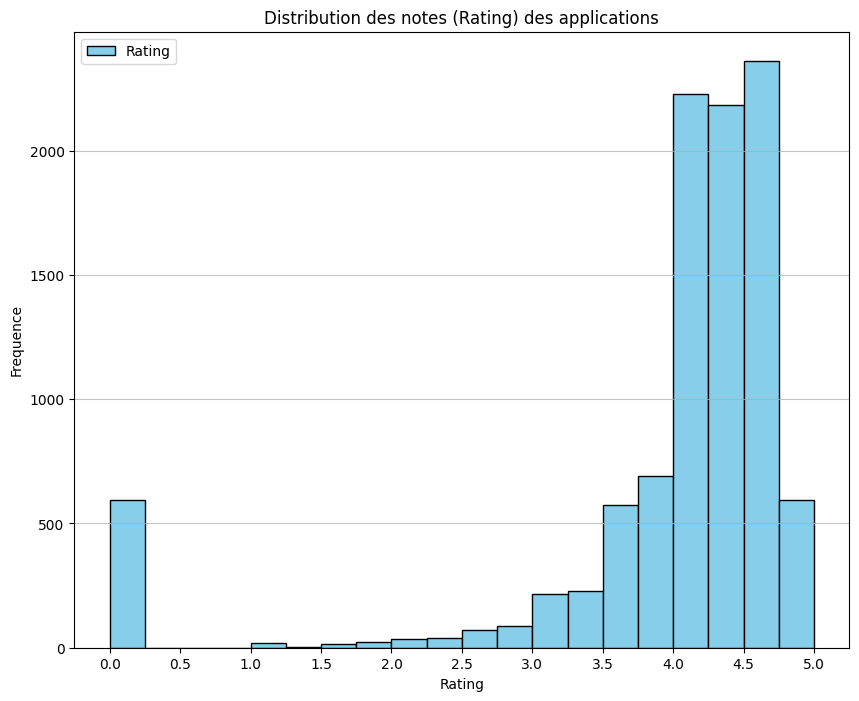

In [46]:
plt.figure(figsize=(10, 8))
plt.hist(data["Rating"], bins=20, color='skyblue', edgecolor="black")
plt.title("Distribution des notes (Rating) des applications")
plt.xlabel("Rating")
plt.ylabel("Frequence")
plt.legend(["Rating"])
plt.grid(axis='y', alpha=0.75)
plt.xticks([i/2 for i in range(0,11)]) # affiche les ticks de 0 à 5 avec un pas de 0.5 (i/2)
plt.savefig("Distribution Rating.png", dpi= 300, bbox_inches="tight")
plt.show()

l'histogramme affiche que la distribution de Rating est une distribution negative danc on remplit les valeur manquantes par la mediane

In [47]:
# dandan = data["Rating"]
dandan= (data["Rating"].fillna(data["Rating"].median(), inplace = True))


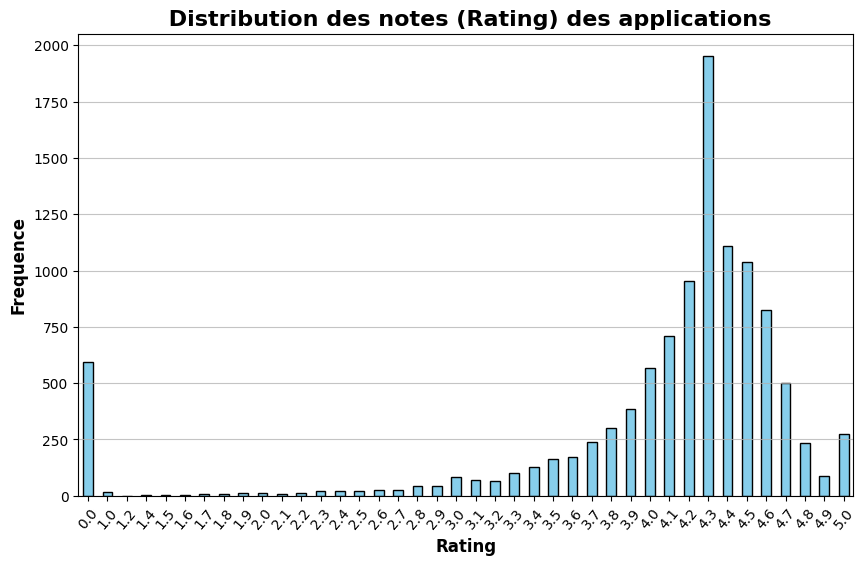

In [48]:
data["Rating"].value_counts().sort_index().plot(kind="bar", figsize=(10, 6), color='skyblue', edgecolor="black")
plt.title(" Distribution des notes (Rating) des applications", fontdict={'fontsize': 16, 'fontweight': 'bold'})
plt.xlabel("Rating", fontsize=12, fontweight='bold')
plt.ylabel('Frequence', fontsize=12, fontweight='bold')
plt.grid(axis='y',alpha=0.75)
plt.xticks(rotation=50)
plt.savefig("Frequence Rating.png", dpi= 200, bbox_inches="tight")
plt.show()

Remplie la Valeur manquante de colnne "Type" par free car le "Price est 0

In [49]:
data['Type'] = data['Type'].fillna("Free")


In [50]:
df_apps_clean = data.copy()
print(df_apps_clean.shape)
df_apps_clean.head(5)

(10841, 10)


,App,Category,Rating,Reviews,Size_MBs,Installs,Type,Price,Content_Rating,Genres
0,Ak Parti Yardım Toplama,SOCIAL,0.0,0,8.7,0,Paid,$13.99,Teen,Social
1,Ain Arabic Kids Alif Ba ta,FAMILY,0.0,0,33.0,0,Paid,$2.99,Everyone,Education
2,Popsicle Launcher for Android P 9.0 launcher,PERSONALIZATION,0.0,0,5.5,0,Paid,$1.49,Everyone,Personalization
3,Command & Conquer: Rivals,FAMILY,0.0,0,19.0,0,Free,0,Everyone 10+,Strategy
4,CX Network,BUSINESS,0.0,0,10.0,0,Free,0,Everyone,Business


In [51]:
df_apps_clean.isnull().sum()

App               0
Category          0
Rating            0
Reviews           0
Size_MBs          0
Installs          0
Type              0
Price             0
Content_Rating    0
Genres            0
dtype: int64

In [52]:
df_apps_clean['App'].count()

np.int64(10841)

5. Y a-t-il des doublons dans les données ? Vérifiez les doublons en utilisant la fonction .duplicated(). Combien d'entrées pouvez-vous trouver pour l'application "Instagram"? Utilisez .drop_duplicates() pour supprimer tous les doublons de df_apps_clean.

In [53]:
print("Nombre de lignes en double :", df_apps_clean.duplicated().sum())

instagram_count = df_apps_clean[df_apps_clean['App'] == 'Instagram'].shape[0]
print(f"Nombre d'entrees pour 'Instagram' avant suppression : {instagram_count}")

df_apps_clean = df_apps_clean.drop_duplicates(subset=['App'])
print("Dimension après suppression des doublons :", df_apps_clean.shape)

Nombre de lignes en double : 485
Nombre d'entrees pour 'Instagram' avant suppression : 4
Dimension après suppression des doublons : (9660, 10)


In [54]:
df_apps_clean.shape

(9660, 10)

In [55]:
df_apps_clean.notnull().sum()

App               9660
Category          9660
Rating            9660
Reviews           9660
Size_MBs          9660
Installs          9660
Type              9660
Price             9660
Content_Rating    9660
Genres            9660
dtype: int64

In [56]:
df_apps_clean['App'].count()

np.int64(9660)

6. Identifiez quelles applications sont les mieux notées. Quel problème pourriez-vous rencontrer si vous vous fiez uniquement aux notes pour évaluer la qualité d'une application ?

In [57]:
top_rated_apps = df_apps_clean[df_apps_clean['Rating'] == 5.0]
print(f"Nombre d'applications notées 5.0 : {top_rated_apps.shape[0]}")
top_rated_apps[['App', 'Category', 'Rating', 'Reviews']].head(10)

Nombre d'applications notées 5.0 : 271


,App,Category,Rating,Reviews
21,KBA-EZ Health Guide,MEDICAL,5.0,4
28,Ra Ga Ba,GAME,5.0,2
47,Mu.F.O.,GAME,5.0,2
82,Brick Breaker BR,GAME,5.0,7
99,Anatomy & Physiology Vocabulary Exam Review App,MEDICAL,5.0,1
126,Tablet Reminder,MEDICAL,5.0,4
128,CQ ESPM,BUSINESS,5.0,2
141,Clinic Doctor EHr,MEDICAL,5.0,2
151,EB Cash Collections,BUSINESS,5.0,1
154,CZ-Help,BOOKS_AND_REFERENCE,5.0,2


Réponse  : Si l'on se fie uniquement à la note de 5.0, on risque de sélectionner des applications qui n'ont presque aucun avis (par exemple, seulement 1 ou 2 avis). Une application avec 1 seul avis 5 étoiles apparaîtra mieux classée qu'une application très populaire ayant une note moyenne de 4.8 avec des millions de téléchargements et de critiques.

7. Trouvez les 5 plus grandes applications en termes de taille (en Mo).

In [58]:
df_apps_clean['Size_MBs'] = pd.to_numeric(df_apps_clean['Size_MBs'], errors='coerce')

top_large_apps = df_apps_clean.sort_values(by='Size_MBs', ascending=False).head(5)
top_large_apps[['App', 'Size_MBs', 'Category']]

,App,Size_MBs,Category
8719,Draft Simulator for FUT 18,100.0,SPORTS
8718,Mini Golf King - Multiplayer Game,100.0,GAME
4176,Car Crash III Beam DH Real Damage Simulator 2018,100.0,GAME
10295,SimCity BuildIt,100.0,FAMILY
9945,Ultimate Tennis,100.0,SPORTS


In [59]:
df_apps_clean["Size_MBs"].dtype

dtype('float64')

8. Quelles applications ont le plus grand nombre de critiques (Reviews) ? Y a-t-il des applications payantes parmi les 50 premières ?

In [60]:
df_apps_clean['Reviews'] = pd.to_numeric(df_apps_clean['Reviews'], errors='coerce')

top_reviews = df_apps_clean.sort_values(by='Reviews', ascending=False).head(50)

paid_top_50 = top_reviews[top_reviews['Type'] == 'Paid']
print(f"Nombre d'applications payantes dans le top 50 des critiques : {paid_top_50.shape[0]}")
top_reviews[['App', 'Reviews', 'Category', 'Type']].head(5)

Nombre d'applications payantes dans le top 50 des critiques : 0


,App,Reviews,Category,Type
10805,Facebook,78158306,SOCIAL,Free
10785,WhatsApp Messenger,69119316,COMMUNICATION,Free
10806,Instagram,66577313,SOCIAL,Free
10784,Messenger – Text and Video Chat for Free,56642847,COMMUNICATION,Free
10650,Clash of Clans,44891723,GAME,Free


9. Visualise Categorical Data: Content Ratings en utilisant Plotly Pie and Donut Charts.

In [61]:
# import plotly.express as px

# content_counts = df_apps_clean['Content_Rating'].value_counts()

# fig = px.pie(names=content_counts.index, values=content_counts.values, title="Repartition des applications par Content Rating") 
# fig.update_traces(textinfo='percent+label')

# plt.savefig("Pie repartition apps par Content Rating.png", dpi=200)
# fig.show()

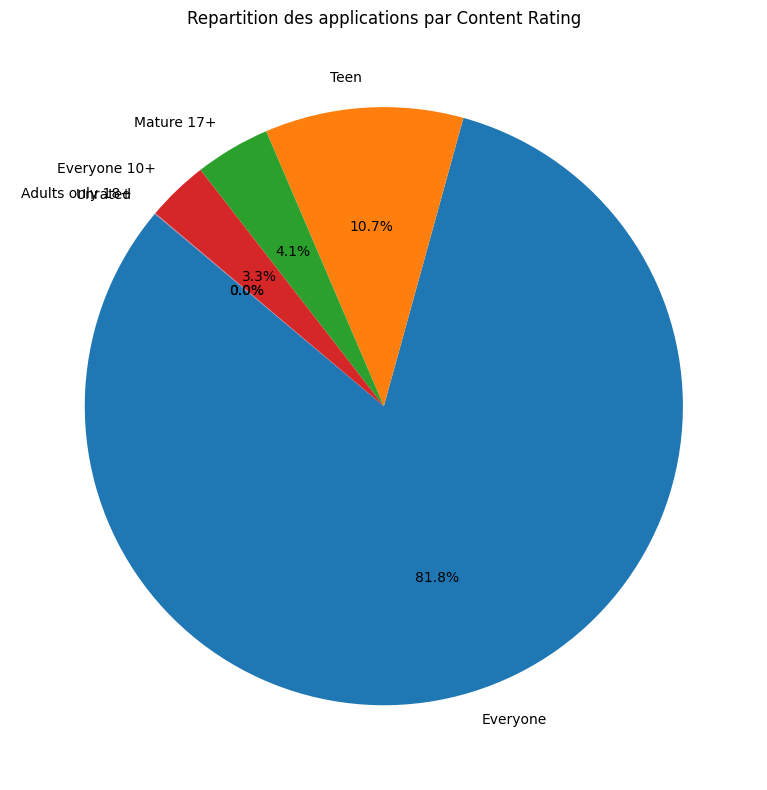

In [62]:
content_counts = df_apps_clean['Content_Rating'].value_counts()
plt.figure(figsize=(8, 8))
plt.pie(
    content_counts.values, 
    labels=content_counts.index, 
    autopct='%1.1f%%', 
    startangle=140)
plt.title("Repartition des applications par Content Rating")
plt.tight_layout()
plt.savefig("Pie repartition apps par Content Rating.png", dpi=200, bbox_inches="tight")
plt.show()

10. Combien d'applications ont été installées plus d'un milliard de fois ? Combien d'applications n'ont été installées qu'une seule fois ?

In [63]:
df_apps_clean['Installs'] = df_apps_clean['Installs'].astype(str).str.replace(',', '').str.replace('+', '').astype(int)

install_counts = df_apps_clean['Installs'].value_counts().sort_index(ascending=False)
print("Nombre d'applications par niveau d'installation :\n", install_counts)

billion_installs = (df_apps_clean['Installs'] >= 1000000000).sum()
single_install = (df_apps_clean['Installs'] == 1).sum()

print(f"\n> Applications installées plus d'un milliard de fois : {billion_installs}")
print(f"-> Applications installées exactement une seule fois : {single_install}")

Nombre d'applications par niveau d'installation :
 Installs
1000000000      20
500000000       24
100000000      188
50000000       202
10000000       933
5000000        606
1000000       1419
500000         505
100000        1113
50000          469
10000         1032
5000           468
1000           890
500            328
100            710
50             204
10             385
5               82
1               67
0               15
Name: count, dtype: int64

> Applications installées plus d'un milliard de fois : 20
-> Applications installées exactement une seule fois : 67


11. Trouvez les applications les plus chères:

In [64]:
df_apps_clean['Price'] = df_apps_clean['Price'].astype(str).str.replace('$', '').str.replace('Everyone', '0').astype(float)

top_expensive = df_apps_clean.sort_values(by='Price', ascending=False).head(10)
top_expensive[['App', 'Price', 'Category']].head(10)



,App,Price,Category
3946,I'm Rich - Trump Edition,400.00,LIFESTYLE
1331,most expensive app (H),399.99,FAMILY
3145,I am rich(premium),399.99,FINANCE
1946,I am rich (Most expensive app),399.99,FINANCE
2394,I am Rich!,399.99,FINANCE
2775,I Am Rich Pro,399.99,FAMILY
4606,I Am Rich Premium,399.99,FINANCE
3114,I am Rich,399.99,FINANCE
5765,I am rich,399.99,LIFESTYLE
2461,I AM RICH PRO PLUS,399.99,FINANCE


In [65]:
df_apps_clean['Revenue_Estimate'] = df_apps_clean['Price'] * df_apps_clean['Installs']

top_revenue = df_apps_clean.sort_values(by='Revenue_Estimate', ascending=False).head(10)
print("Top 10 applications les plus rentables :")
display(top_revenue[['App', 'Price', 'Installs', 'Revenue_Estimate']])

games_count = top_revenue[top_revenue['Category'] == 'GAME'].shape[0]
print(f"Nombre de jeux parmi les 10 applications payantes les plus rentables : {games_count}")

Top 10 applications les plus rentables :


,App,Price,Installs,Revenue_Estimate
9220,Minecraft,6.99,10000000,69900000.0
5765,I am rich,399.99,100000,39999000.0
4606,I Am Rich Premium,399.99,50000,19999500.0
8825,Hitman Sniper,0.99,10000000,9900000.0
7151,Grand Theft Auto: San Andreas,6.99,1000000,6990000.0
7977,Sleep as Android Unlock,5.99,1000000,5990000.0
7477,Facetune - For Free,5.99,1000000,5990000.0
6594,DraStic DS Emulator,4.99,1000000,4990000.0
3946,I'm Rich - Trump Edition,400.00,10000,4000000.0
3221,I am Rich Plus,399.99,10000,3999900.0


Nombre de jeux parmi les 10 applications payantes les plus rentables : 3


12. & 13. Analyse des catégories d'applications (Histogramme et Bar Chart Horizontal)

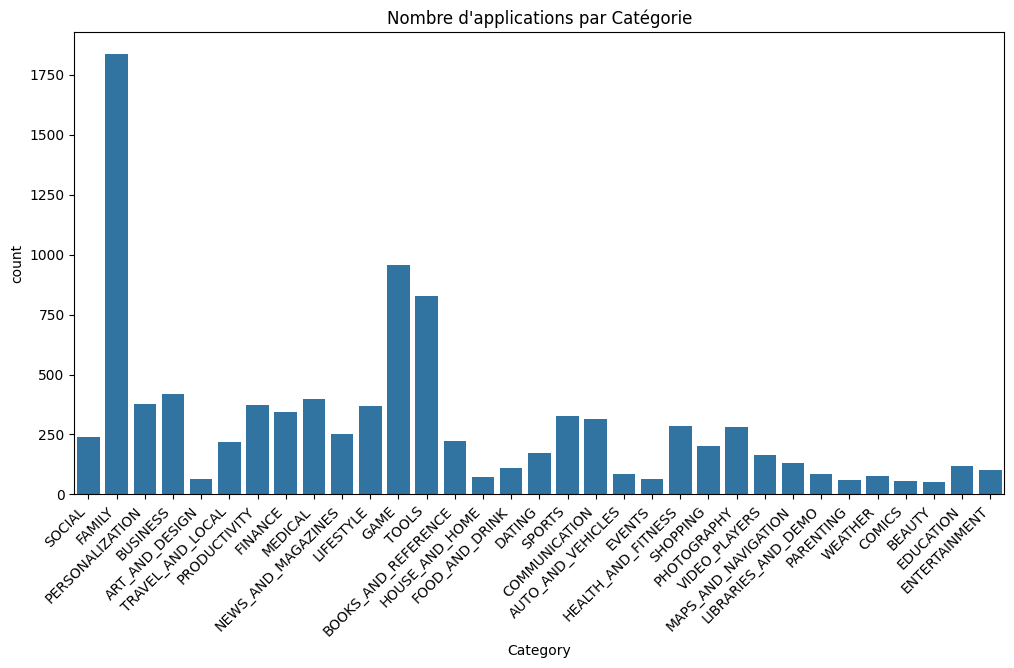

In [66]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df_apps_clean, x='Category')
plt.title("Nombre d'applications par Catégorie")
plt.xticks(rotation=45, ha='right') # Incline les étiquettes
plt.savefig("Nombre d'applications par Categorie.png", dpi=200, bbox_inches="tight")
plt.show()

C:\Users\moham\AppData\Local\Temp\ipykernel_26228\145625511.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_installs, x='Installs', y='Category', palette='viridis')


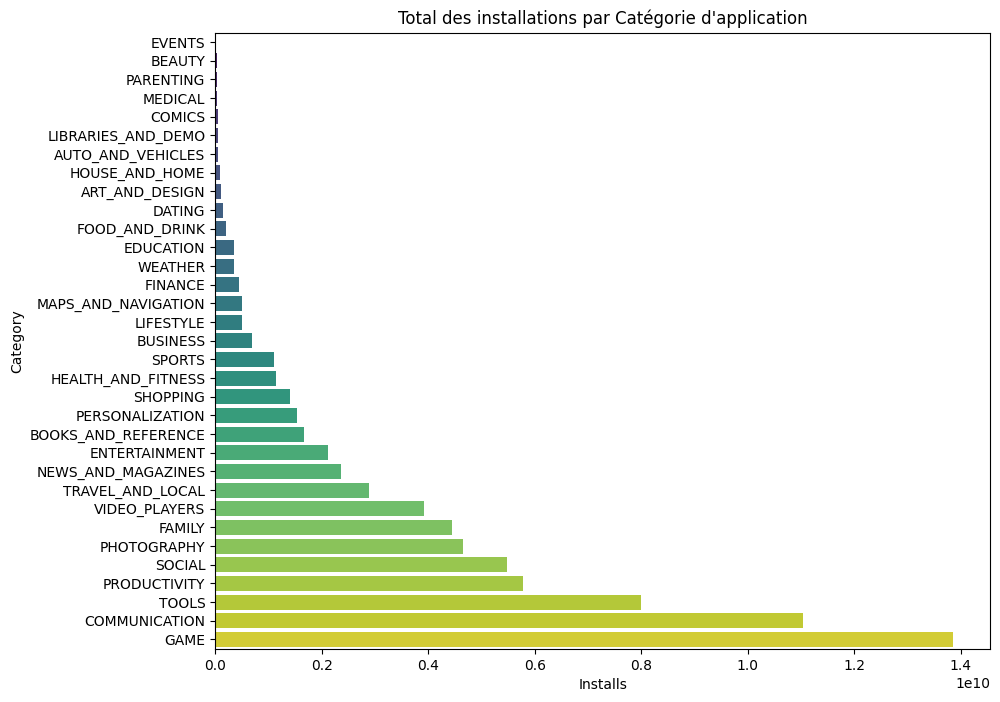

In [67]:
category_installs = df_apps_clean.groupby('Category')['Installs'].sum().reset_index().sort_values(by='Installs', ascending=True)
plt.figure(figsize=(10, 8))
sns.barplot(data=category_installs, x='Installs', y='Category', palette='viridis')
plt.title("Total des installations par Catégorie d'application")
plt.xlabel("Installs")
plt.ylabel("Category")
plt.savefig("Total des installations par Catégorie d'application.png", dpi=200, bbox_inches="tight")
plt.show()

In [68]:
# fig_cat = px.histogram(df_apps_clean, x='Category', title="Nombre d'applications par Catégorie")
# fig_cat.update_layout(xaxis_tickangle=-45)
# # plt.savefig("Nombre d'applications par Catégorie.png", dpi=200, bbox_inches="tight")
# fig_cat.show()


# category_installs = df_apps_clean.groupby('Category')['Installs'].sum().reset_index().sort_values(by='Installs', ascending=True)
# fig_installs = px.bar(category_installs, x='Installs', y='Category', orientation='h', title="Total des installations par Catégorie d'application")
# # plt.savefig("Total des installations par Catégorie d'application.png", dpi=200, bbox_inches="tight")
# fig_installs.show()

14. Concentration des catégories - Téléchargements vs. Concurrence: 
a. Créez un DataFrame avec les colonnes catégories, le nombre 
d'applications et le nombre d'installations. 
b. Utiliser scatterplot() pour visualiser le nombre d’installations en fonction 
nombre d’applications. Ajouter aussi les catégories. 
c. À votre avis, quelles sont les meilleures catégories que vous jugez 
idéales et plus rentables en termes d’argent pour développer une 
application. 

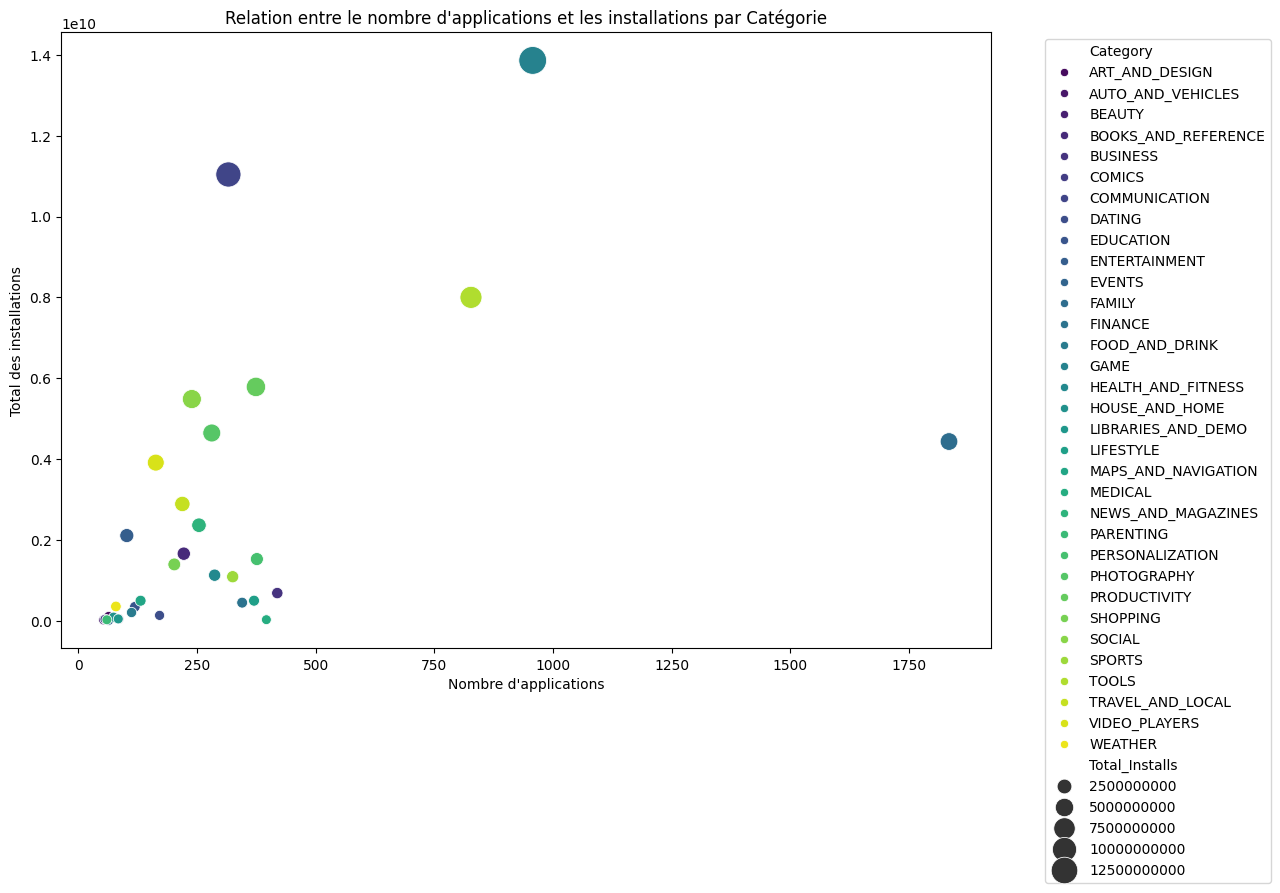

In [69]:
# 1. Préparation des données (votre code d'origine)
cat_summary = df_apps_clean.groupby('Category').agg(
    App_Count=('App', 'count'),
    Total_Installs=('Installs', 'sum')).reset_index()
plt.figure(figsize=(12, 8))
# 3. Création du nuage de points avec Seaborn (scatterplot)
# - x : nombre d'apps, y : total des installations
# - size : taille des points selon les installations
# - hue : couleur selon la catégorie
sns.scatterplot(
    data=cat_summary, 
    x='App_Count', 
    y='Total_Installs', 
    size='Total_Installs', 
    hue='Category', 
    sizes=(50, 400), # Ajuste la taille min et max des points
    palette='viridis', 
    legend='brief')
plt.title("Relation entre le nombre d'applications et les installations par Catégorie")
plt.xlabel("Nombre d'applications")
plt.ylabel("Total des installations")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.savefig("Relation entre le nombre d'applications et les installations par Catégorie.png", dpi=200, bbox_inches="tight")
plt.show()

In [70]:
# cat_summary = df_apps_clean.groupby('Category').agg(App_Count=('App', 'count'),Total_Installs=('Installs', 'sum')).reset_index()

# fig_scatter = px.scatter(cat_summary, x='App_Count', y='Total_Installs', size='Total_Installs',
#     color='Category', hover_name='Category',
#     title="Relation entre le nombre d'applications et les installations par Catégorie")
# plt.savefig("Relation entre le nombre d'applications et les installations par Catégorie.png", dpi=200, bbox_inches="tight")
# fig_scatter.show()

c. Analyse / Interprétation : Les catégories idéales et plus rentables combinent une forte demande (nombre élevé d'installations) avec une concurrence maîtrisée (nombre d'applications modéré). Des segments comme les Jeux (GAME), les Outils (TOOLS) ou la Famille (FAMILY) génèrent un volume massif de téléchargements, tandis que des niches spécialisées (comme Finance ou Productivity) offrent d'excellentes opportunités de monétisation directe ou d'abonnements avec moins de saturation directe.
